In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

In [2]:
iris = load_iris(as_frame=True)

df = iris.frame

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [3]:
X = df.iloc[:, :4]

X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [4]:
X.columns

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)'],
      dtype='object')

In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled[:5]

array([[-0.90068117,  1.01900435, -1.34022653, -1.3154443 ],
       [-1.14301691, -0.13197948, -1.34022653, -1.3154443 ],
       [-1.38535265,  0.32841405, -1.39706395, -1.3154443 ],
       [-1.50652052,  0.09821729, -1.2833891 , -1.3154443 ],
       [-1.02184904,  1.24920112, -1.34022653, -1.3154443 ]])

In [6]:
inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than availabl

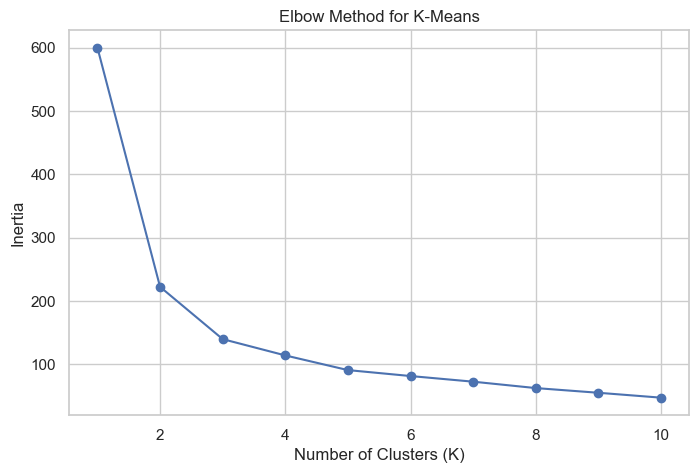

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), inertia, marker="o")

plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.show()

In [8]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

kmeans_clusters = kmeans.fit_predict(X_scaled)

kmeans_clusters

D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 2, 2, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 2,
       0, 0, 0, 0, 2, 0, 0, 0, 0, 2, 2, 2, 0, 0, 0, 0, 0, 0, 0, 2, 2, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 2, 2, 2, 0, 2, 2, 2,
       2, 2, 2, 0, 0, 2, 2, 2, 2, 0, 2, 0, 2, 0, 2, 2, 0, 2, 2, 2, 2, 2,
       2, 0, 0, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 0], dtype=int32)

In [9]:
df["KMeans_Cluster"] = kmeans_clusters

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,KMeans_Cluster
0,5.1,3.5,1.4,0.2,0,1
1,4.9,3.0,1.4,0.2,0,1
2,4.7,3.2,1.3,0.2,0,1
3,4.6,3.1,1.5,0.2,0,1
4,5.0,3.6,1.4,0.2,0,1


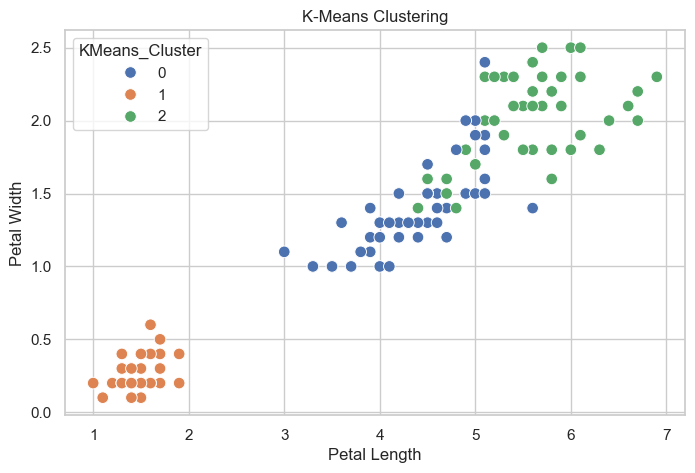

In [10]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X["petal length (cm)"],
    y=X["petal width (cm)"],
    hue=df["KMeans_Cluster"],
    palette="deep",
    s=70
)

plt.title("K-Means Clustering")
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")

plt.show()

In [11]:
kmeans_score = silhouette_score(X_scaled, kmeans_clusters)

print("K-Means Silhouette Score:", kmeans_score)

K-Means Silhouette Score: 0.45994823920518646


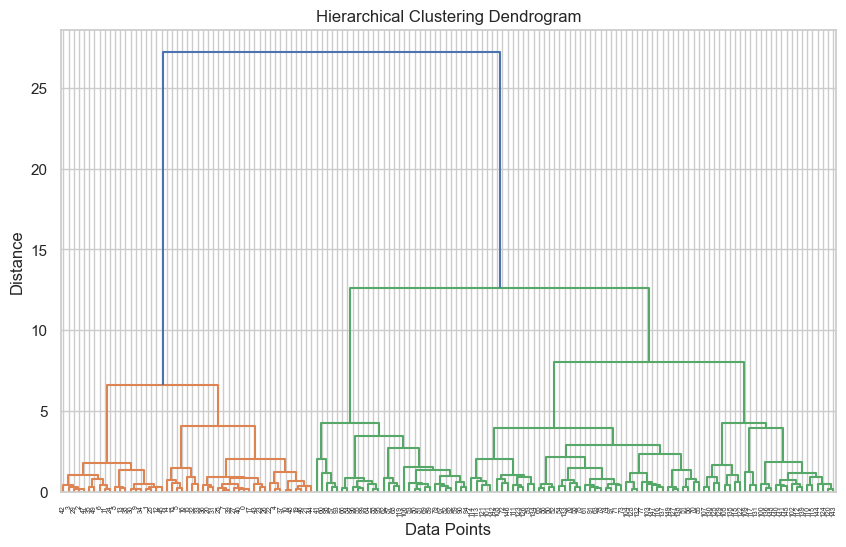

In [12]:
linked = linkage(X_scaled, method="ward")

plt.figure(figsize=(10, 6))

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")

plt.show()

In [13]:
hierarchical = AgglomerativeClustering(n_clusters=3)

hierarchical_clusters = hierarchical.fit_predict(X_scaled)

hierarchical_clusters

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 0, 2, 0, 2, 0, 2, 0, 2, 2, 0, 2, 0, 2, 0,
       2, 2, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 0, 2, 0, 0, 2,
       2, 2, 2, 0, 2, 2, 2, 2, 2, 0, 2, 2, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [14]:
df["Hierarchical_Cluster"] = hierarchical_clusters

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,KMeans_Cluster,Hierarchical_Cluster
0,5.1,3.5,1.4,0.2,0,1,1
1,4.9,3.0,1.4,0.2,0,1,1
2,4.7,3.2,1.3,0.2,0,1,1
3,4.6,3.1,1.5,0.2,0,1,1
4,5.0,3.6,1.4,0.2,0,1,1


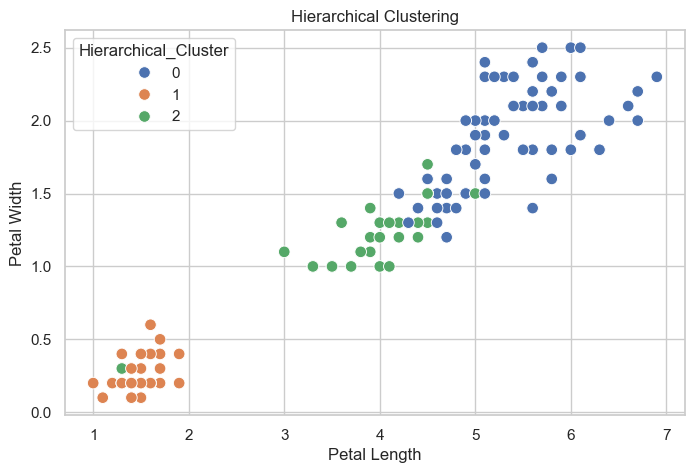

In [15]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X["petal length (cm)"],
    y=X["petal width (cm)"],
    hue=df["Hierarchical_Cluster"],
    palette="deep",
    s=70
)

plt.title("Hierarchical Clustering")
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")

plt.show()

In [16]:
hierarchical_score = silhouette_score(
    X_scaled,
    hierarchical_clusters
)

print("Hierarchical Silhouette Score:", hierarchical_score)

Hierarchical Silhouette Score: 0.446689041028591


In [17]:
dbscan = DBSCAN(eps=0.8, min_samples=5)

dbscan_clusters = dbscan.fit_predict(X_scaled)

dbscan_clusters

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1, -1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1])

In [18]:
df["DBSCAN_Cluster"] = dbscan_clusters

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,KMeans_Cluster,Hierarchical_Cluster,DBSCAN_Cluster
0,5.1,3.5,1.4,0.2,0,1,1,0
1,4.9,3.0,1.4,0.2,0,1,1,0
2,4.7,3.2,1.3,0.2,0,1,1,0
3,4.6,3.1,1.5,0.2,0,1,1,0
4,5.0,3.6,1.4,0.2,0,1,1,0


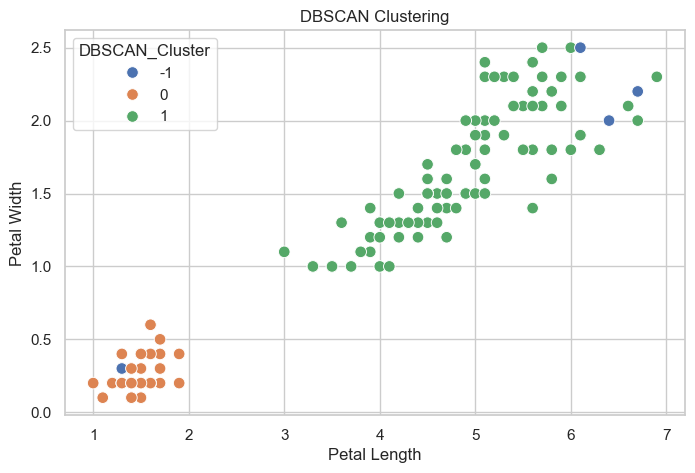

In [19]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X["petal length (cm)"],
    y=X["petal width (cm)"],
    hue=df["DBSCAN_Cluster"],
    palette="deep",
    s=70
)

plt.title("DBSCAN Clustering")
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")

plt.show()

In [20]:
labels = dbscan_clusters

if len(set(labels)) > 1:
    dbscan_score = silhouette_score(X_scaled, labels)
    print("DBSCAN Silhouette Score:", dbscan_score)
else:
    print("Silhouette Score cannot be calculated.")

DBSCAN Silhouette Score: 0.5216965052515835


In [21]:
results = pd.DataFrame({
    "Clustering Technique": [
        "K-Means",
        "Hierarchical",
        "DBSCAN"
    ],
    "Silhouette Score": [
        kmeans_score,
        hierarchical_score,
        dbscan_score
    ]
})

results

,Clustering Technique,Silhouette Score
0,K-Means,0.460
1,Hierarchical,0.447
2,DBSCAN,0.522
